# Exploration des zusammengeführten Katalogs

Drei Fragen:

1. Ist `data/merged/filme.csv` das passende Set für unser Vorhaben?
2. Was hat es mit den italienischen Titeln auf sich, und stehen die nach dem Merge noch in der Tabelle?
3. Warum sind es nicht rund 120.000 Filme, obwohl wir zwei Kataloge zusammengeführt haben?

Das Vorhaben bleibt: fünf Empfehlungen, davon mindestens zwei kulturell neu. Kulturell neu heißt Produktionsland außerhalb von USA und UK und Originalsprache nicht Englisch. Der Geschmack kommt aus Genres und drei Referenzfilmen, die Bekanntheit aus den IMDb-Stimmen.

Abschnitt 5 zeigt dieselben Verhältnisse in Diagrammen.


## 1. Katalog laden

Wir lesen die fertige Filmtabelle und daneben nur die Titelspalten der beiden Quellen. So lässt sich zeigen, welcher Name woher kommt.


In [7]:
import pandas as pd

pd.set_option("display.max_colwidth", 55)

def de(zahl):
    return f"{int(zahl):,}".replace(",", ".")

filme = pd.read_csv("data/merged/filme.csv", low_memory=False)
imdb = pd.read_csv(
    "data/github/IMDb movies.csv",
    usecols=["imdb_title_id", "title", "original_title"],
    low_memory=False,
)
meta = pd.read_csv(
    "data/kaggle/movies_metadata.csv",
    usecols=["imdb_id"],
    low_memory=False,
)

print(f"Zusammengeführte Filme: {de(len(filme))}")
print(f"Spalten: {', '.join(filme.columns)}")


Zusammengeführte Filme: 85.855
Spalten: imdb_id, tmdb_id, titel, originaltitel, jahr, genre, land, sprache, originalsprache, studios, regie, darsteller, beschreibung, schlagwoerter, imdb_bewertung, imdb_stimmen


## 2. Warum es keine 120.000 Filme sind

85.855 IMDb-Filme plus 45.466 TMDB-Zeilen ergeben 131.321 Zeilen. Das ist keine Anzahl verschiedener Filme. Rund 34.000 Filme stehen in beiden Dateien. Wer die Zeilen addiert, zählt diese Filme doppelt.

Eindeutige Filme über die IMDb-ID: die IMDb-Filme plus die TMDB-Filme, deren ID bei IMDb fehlt. Das sind etwa 97.000, nicht 120.000.

Unsere Tabelle hat genau 85.855 Zeilen, also jeden IMDb-Film einmal. Die Filme, die nur TMDB kennt, wurden nicht angehängt. Ein linker Join vervielfacht die linke Tabelle nicht und nimmt die rechte nur dort dazu, wo die ID schon vorkommt.


In [8]:
imdb_ids = set(imdb["imdb_title_id"].astype(str))
meta_ids = {
    wert for wert in meta["imdb_id"].dropna().astype(str)
    if wert.startswith("tt")
}
beide = imdb_ids & meta_ids
nur_imdb = imdb_ids - meta_ids
nur_tmdb = meta_ids - imdb_ids

bilanz = pd.DataFrame({
    "Was": [
        "Zeilen in der IMDb-Datei",
        "Zeilen in der TMDB-Datei",
        "Summe der Zeilen, Filme doppelt gezählt",
        "Dieselbe IMDb-ID in beiden Dateien",
        "Nur bei IMDb",
        "Nur bei TMDB",
        "Verschiedene Filme in beiden Dateien zusammen",
        "Zeilen in unserer Filmtabelle",
    ],
    "Anzahl": [
        len(imdb),
        len(meta),
        len(imdb) + len(meta),
        len(beide),
        len(nur_imdb),
        len(nur_tmdb),
        len(imdb_ids | meta_ids),
        len(filme),
    ],
})
bilanz["Anzahl"] = bilanz["Anzahl"].map(de)
bilanz


,Was,Anzahl
0,Zeilen in der IMDb-Datei,85.855
1,Zeilen in der TMDB-Datei,45.466
2,"Summe der Zeilen, Filme doppelt gezählt",131.321
3,Dieselbe IMDb-ID in beiden Dateien,34.073
4,Nur bei IMDb,51.782
5,Nur bei TMDB,11.343
6,Verschiedene Filme in beiden Dateien zusammen,97.198
7,Zeilen in unserer Filmtabelle,85.855


### Was die nur-TMDB-Filme wären

Die etwa 11.000 Filme, die wir weggelassen haben, sind zum größten Teil englischsprachig. Darunter sind Fortsetzungen, Kurzfilme und Serienableger. Sie würden die Lücke bei der Originalsprache der IMDb-Filme nicht schließen. Für die kulturelle Mischung ist ihr Fehlen deshalb klein.


In [9]:
meta_voll = pd.read_csv(
    "data/kaggle/movies_metadata.csv",
    usecols=["imdb_id", "title", "original_language", "vote_count"],
    low_memory=False,
)
nur = meta_voll[meta_voll["imdb_id"].astype(str).isin(nur_tmdb)].copy()
nur["vote_count"] = pd.to_numeric(nur["vote_count"], errors="coerce")
nur = nur.sort_values("vote_count", ascending=False).drop_duplicates("imdb_id")

anteil_englisch = (nur["original_language"] == "en").mean()
print(f"Nur-TMDB-Filme: {de(len(nur))}")
print(f"Davon Originalsprache Englisch: {anteil_englisch:.0%}")
nur[["title", "original_language", "vote_count"]].head(6)


Nur-TMDB-Filme: 11.343
Davon Originalsprache Englisch: 82%


,title,original_language,vote_count
11034,High School Musical,en,1048.0
9115,The Lion King 2: Simba's Pride,en,1034.0
12882,High School Musical 2,en,884.0
30061,Kung Fury,en,762.0
19901,Paperman,en,734.0
43190,Band of Brothers,en,725.0


## 3. Die italienischen Namen

In der IMDb-Datei gibt es zwei Namen:

- `title` ist oft der **italienische Verleihtitel**, zum Beispiel `Il grande Gatsby`
- `original_title` ist der **Originaltitel**, zum Beispiel `The Great Gatsby`

Das betrifft vor allem Filme, die nicht aus Italien kommen. Der italienische Name ist dann eine Übersetzung für den italienischen Markt, nicht die Sprache des Films.

Beim Merge haben wir `title` aus der IMDb-Datei nicht übernommen. Der Anzeigetitel `titel` ist der TMDB-Titel, wenn es einen gibt, sonst der Originaltitel. `originaltitel` speichert den Originaltitel zusätzlich.


In [10]:
vergleich = filme.merge(
    imdb.rename(columns={
        "imdb_title_id": "imdb_id",
        "title": "titel_imdb",
        "original_title": "original_imdb",
    }),
    on="imdb_id",
    how="left",
)

anders = (
    vergleich["titel_imdb"].fillna("").str.casefold()
    != vergleich["original_imdb"].fillna("").str.casefold()
)
print(f"IMDb-Titel und Originaltitel verschieden: {de(anders.sum())} von {de(len(vergleich))}")

beispiele = vergleich[
    vergleich["titel_imdb"].str.match(r"^(Il|Lo|La|I|Gli|Le|L')\b", case=False, na=False)
    & anders
][["titel_imdb", "original_imdb", "titel", "tmdb_id"]].head(8)
beispiele


IMDb-Titel und Originaltitel verschieden: 23.341 von 85.855


,titel_imdb,original_imdb,titel,tmdb_id
12,Il calvario di una madre,Ingeborg Holm,Ingeborg Holm,147622.0
18,Lo studente di Praga,Der Student von Prag,The Student of Prague,28627.0
38,La madonnina del porto,Tess of the Storm Country,Tess of the Storm Country,NaN
51,La vampira,A Fool There Was,A Fool There Was,38730.0
60,La rigenerazione,The Regeneration,Regeneration,86081.0
61,I vampiri,Les vampires,Les vampires,29082.0
94,L'astronave,Himmelskibet,Himmelskibet,NaN
116,Gli occhi della mummia,Die Augen der Mumie Ma,Die Augen der Mumie Ma,NaN


### Stehen die italienischen Verleihtitel noch im Merge?

In der Anzeigespalte `titel` nicht mehr. Wenn der italienische Verleihtitel vom Originaltitel abweicht, ersetzt ihn der Merge. Bei einem TMDB-Treffer steht dort der TMDB-Titel, sonst der Originaltitel.

`Il grande Gatsby` und `Il padrino` kommen in der zusammengeführten Datei nicht vor. Dort heißen die Filme `The Great Gatsby` und `The Godfather`.

Der eine Treffer, den die Suche noch findet, ist `La Vie en Rose`. Das ist der internationale Titel, keine italienische Übersetzung. Italienische Wörter bleiben dort, wo sie hingehören: bei Filmen, deren eigener Titel italienisch ist, etwa `La dolce vita`.


In [11]:
noch_verleihtitel = anders & (
    vergleich["titel"].fillna("").str.casefold()
    == vergleich["titel_imdb"].fillna("").str.casefold()
)
italienisch = vergleich["titel_imdb"].str.match(
    r"^(Il |Lo |La |Gli |L')", case=False, na=False
)
noch_italienisch = italienisch & anders & (
    vergleich["titel"].fillna("").str.casefold()
    == vergleich["titel_imdb"].fillna("").str.casefold()
)
ohne_tmdb = vergleich["tmdb_id"].isna()
print(f"Italienisch anmutender Verleihtitel steht noch als Anzeigetitel: {de(noch_italienisch.sum())}")
vergleich.loc[
    noch_italienisch, ["titel_imdb", "original_imdb", "titel"]
]
print(f"Andere abweichende IMDb-Titel unverändert, meist nur andere Schreibweise: {de((noch_verleihtitel & ~italienisch).sum())}")
print(f"Ohne TMDB-Treffer ist der Anzeigetitel der Originaltitel: {de(ohne_tmdb.sum())} Filme")

print("Suche nach bekannten italienischen Verleihtiteln:")
for name in ["Il grande Gatsby", "Il padrino", "The Great Gatsby", "The Godfather", "La dolce vita"]:
    treffer = filme["titel"].fillna("").str.casefold().eq(name.casefold()).sum()
    print(f"  {name}: {de(treffer)}")

filme.loc[
    filme["titel"].str.casefold().eq("la dolce vita"),
    ["titel", "originaltitel", "land", "originalsprache"],
]


Italienisch anmutender Verleihtitel steht noch als Anzeigetitel: 1
Andere abweichende IMDb-Titel unverändert, meist nur andere Schreibweise: 474
Ohne TMDB-Treffer ist der Anzeigetitel der Originaltitel: 51.782 Filme
Suche nach bekannten italienischen Verleihtiteln:
  Il grande Gatsby: 0
  Il padrino: 0
  The Great Gatsby: 3
  The Godfather: 1
  La dolce vita: 1


,titel,originaltitel,land,originalsprache
10295,La Dolce Vita,La dolce vita,"Italy, France",it


## 4. Reicht das Set für das Vorhaben?

Genre, Land und IMDb-Stimmen sind fast durchgehend da. Damit lassen sich Geschmack und Bekanntheit für alle Filme bestimmen. Die Anzeigetitel sind bereinigt.

Zwei Felder aus TMDB gibt es nur für den Teil mit gemeinsamer ID, also für etwa 40 Prozent:

- `originalsprache` brauchen wir für die strenge Regel „nicht Englisch“. Fehlt sie, bleibt nur die gesprochene `sprache` aus IMDb. Das ist eine Näherung, nicht dieselbe Angabe.
- `schlagwoerter` gibt es noch seltener. Ein Bonus für das Stichwort `independent` trifft deshalb nur einen Teil der Filme.

Kulturell neue Filme sind trotzdem in großer Zahl vorhanden, sobald eine Originalsprache da ist. Die Quote von zwei aus fünf lässt sich daraus füllen.


In [12]:
def anteil_leer(spalte):
    return filme[spalte].isna() | (filme[spalte].astype(str).str.strip().isin(["", "None", "nan", "<NA>"]))

luecken = pd.DataFrame({
    "Spalte": ["genre", "land", "sprache", "originalsprache", "schlagwoerter", "imdb_stimmen", "beschreibung"],
})
luecken["Gefüllt"] = [
    de((~anteil_leer(spalte)).sum()) for spalte in luecken["Spalte"]
]
luecken["Leer"] = [
    de(anteil_leer(spalte).sum()) for spalte in luecken["Spalte"]
]

usa_uk = filme["land"].fillna("").str.contains(r"\bUSA\b|\bUK\b", regex=True)
hat_land = filme["land"].fillna("").str.strip().ne("")
orig = filme["originalsprache"].fillna("")
kulturell_neu = hat_land & ~usa_uk & orig.ne("") & orig.ne("en")

print(f"Mit Originalsprache: {de((orig != '').sum())}")
print(f"Davon kulturell neu (Land nicht USA/UK, Sprache nicht en): {de(kulturell_neu.sum())}")
luecken


Mit Originalsprache: 34.072
Davon kulturell neu (Land nicht USA/UK, Sprache nicht en): 10.522


,Spalte,Gefüllt,Leer
0,genre,85.855,0
1,land,85.791,64
2,sprache,84.954,901
3,originalsprache,34.072,51.783
4,schlagwoerter,24.546,61.309
5,imdb_stimmen,85.855,0
6,beschreibung,83.908,1.947


## 5. Diagramme zu den wichtigen Spalten

Die Bilder zeigen die Spalten, mit denen die Empfehlung arbeitet: Herkunft, Sprache, IMDb-Stimmen und Genre. Dazu die Lücken bei Originalsprache und Schlagwörtern.

### Vollständigkeit

Genre, Land und Stimmen sind fast immer gefüllt. Die Originalsprache fehlt bei rund 60 Prozent, Schlagwörter bei rund 70 Prozent. Das sind genau die beiden Angaben, die nur von TMDB kommen.

### Herkunft

Ein Film kann mehrere Länder haben. Die erste Grafik zählt deshalb Zuordnungen, nicht exklusiv ein Land. Die USA liegen weit vorn, danach Frankreich, UK, Indien und Italien.

Für die Empfehlung zählt eine zweite Frage: Stehen USA oder UK überhaupt in der Länderliste? Knapp die Hälfte der Filme nennt eines der beiden Länder. Die andere Hälfte ist nach dieser Regel außerhalb davon.

### Originalsprache und kulturelle Neuheit

Die Originalsprache liegt nur für Filme mit TMDB-Treffer vor. Dort ist Englisch die größte Gruppe.

Kulturell neu sind Filme mit bekannter Originalsprache, deren Land nicht USA oder UK ist und deren Code nicht `en` ist. Das sind 10.522 Filme. 23.550 sind bei bekannter Sprache vertraut. Bei 51.783 Filmen fehlt die Originalsprache, die strenge Regel lässt sich dort nicht anwenden.

Die unbekannten Fälle sind zugleich die unbekannteren Filme: Der Median der IMDb-Stimmen liegt bei 264, bei den vertrauten Filmen bei 2.498 und bei den kulturell neuen bei 1.389.

### Stimmen und Genres

Die meisten Filme sind nach der Grenze von 40.000 Stimmen nicht hochbekannt. Der Median liegt bei 484 Stimmen, 95,5 Prozent liegen bei höchstens 40.000. Die Grenze schneidet also nur einen kleinen, sehr bekannten Rest ab.

Bei den Genres dominieren Drama und Komödie. Ein Film kann mehrere Genres haben, die Balken sind wieder Zuordnungen.

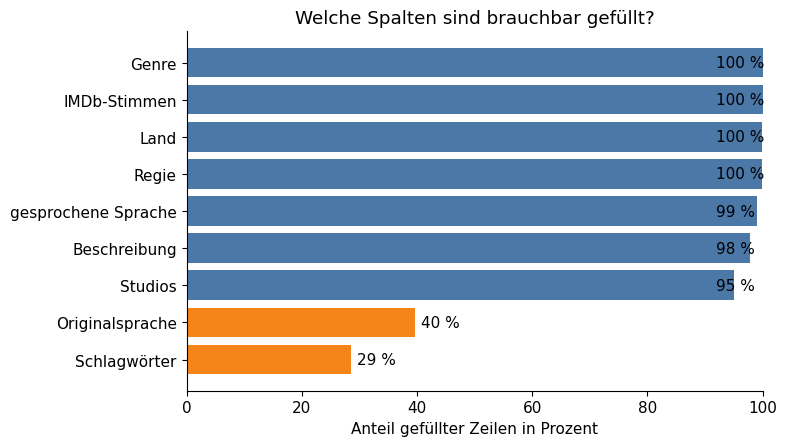

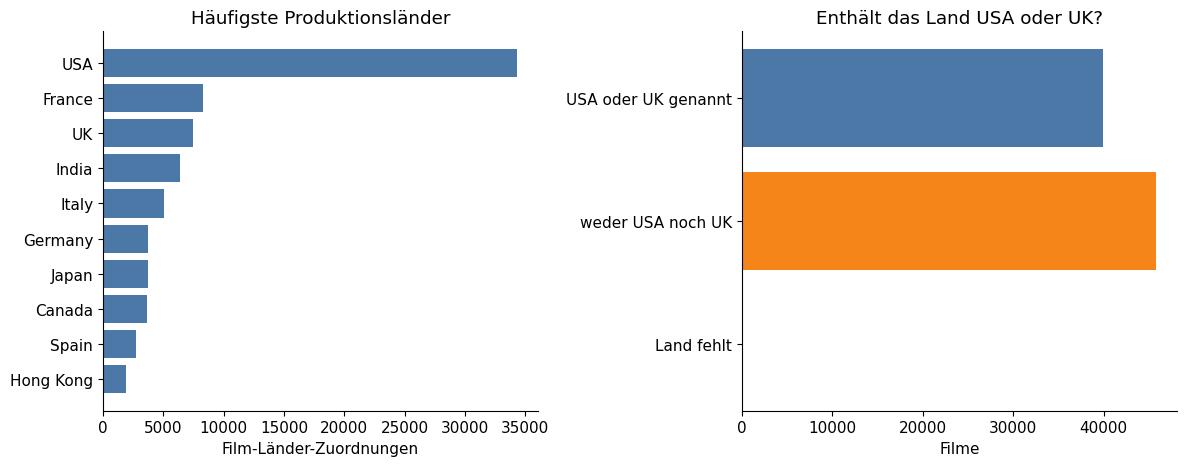

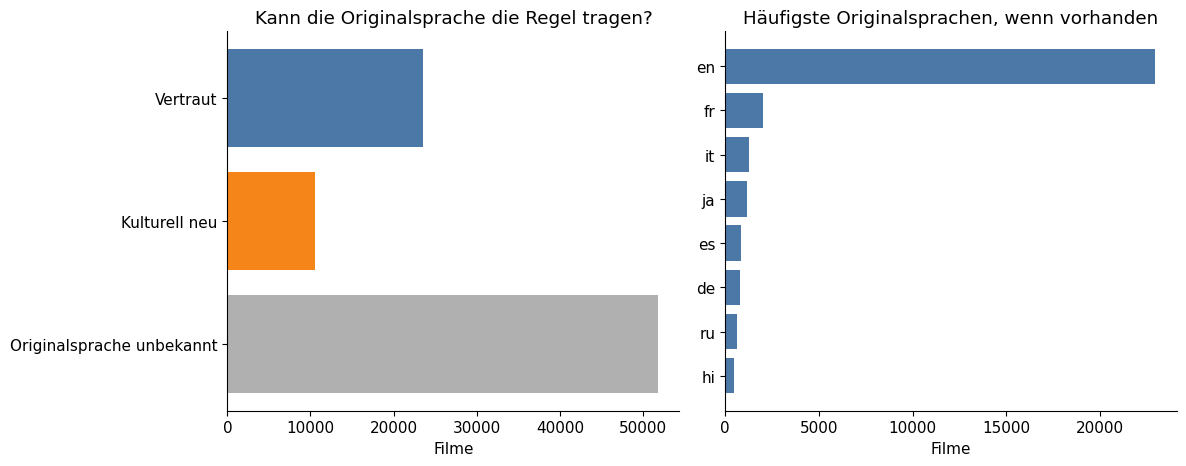

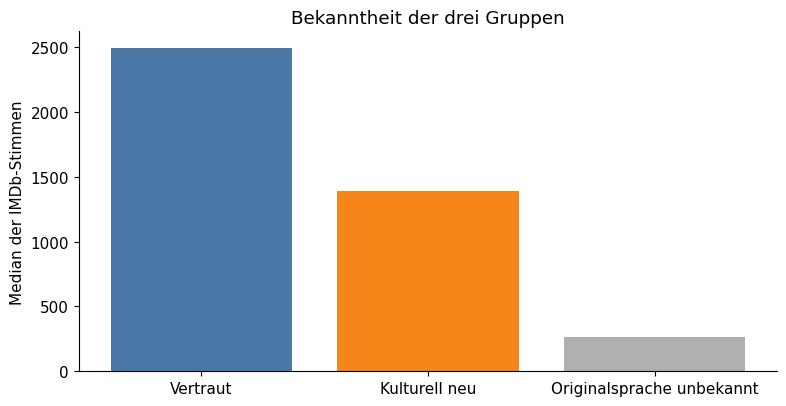

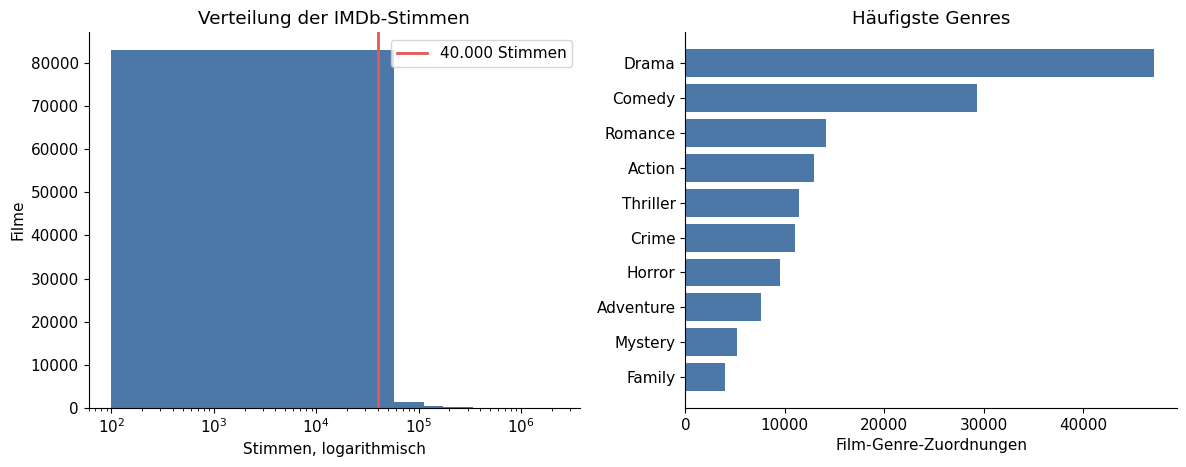

Median der Stimmen: 484
Filme mit höchstens 40.000 Stimmen: 95.5%


In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

def leer(serie):
    return serie.isna() | serie.astype(str).str.strip().isin(["", "None", "nan", "<NA>"])

spalten = [
    "genre", "imdb_stimmen", "land", "regie", "sprache",
    "beschreibung", "studios", "originalsprache", "schlagwoerter",
]
namen = [
    "Genre", "IMDb-Stimmen", "Land", "Regie", "gesprochene Sprache",
    "Beschreibung", "Studios", "Originalsprache", "Schlagwörter",
]
voll = [100 * (~leer(filme[spalte])).mean() for spalte in spalten]

fig, ax = plt.subplots(figsize=(8, 4.6))
farben = ["#4C78A8" if wert >= 90 else "#F58518" for wert in voll]
ax.barh(namen[::-1], voll[::-1], color=farben[::-1])
ax.set_xlim(0, 100)
ax.set_xlabel("Anteil gefüllter Zeilen in Prozent")
ax.set_title("Welche Spalten sind brauchbar gefüllt?")
for i, wert in enumerate(voll[::-1]):
    ax.text(min(wert + 1, 92), i, f"{wert:.0f} %", va="center")
plt.tight_layout()
plt.show()

laender = filme["land"].fillna("").str.split(",").explode().str.strip()
laender = laender[laender != ""]
top_laender = laender.value_counts().head(10).sort_values()

def nennt_usa_oder_uk(text):
    teile = {teil.strip().casefold() for teil in str(text).split(",")}
    return bool(teile & {"usa", "uk"})

filme["hat_usa_uk"] = filme["land"].fillna("").map(nennt_usa_oder_uk)
land_leer = leer(filme["land"])
herkunft = pd.Series({
    "USA oder UK genannt": int((filme["hat_usa_uk"] & ~land_leer).sum()),
    "weder USA noch UK": int((~filme["hat_usa_uk"] & ~land_leer).sum()),
    "Land fehlt": int(land_leer.sum()),
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].barh(top_laender.index, top_laender.values, color="#4C78A8")
axes[0].set_title("Häufigste Produktionsländer")
axes[0].set_xlabel("Film-Länder-Zuordnungen")
farben_herkunft = {
    "USA oder UK genannt": "#4C78A8",
    "weder USA noch UK": "#F58518",
    "Land fehlt": "#B0B0B0",
}
labels = list(herkunft.index[::-1])
axes[1].barh(labels, [herkunft[name] for name in labels], color=[farben_herkunft[name] for name in labels])
axes[1].set_title("Enthält das Land USA oder UK?")
axes[1].set_xlabel("Filme")
plt.tight_layout()
plt.show()

filme["orig"] = filme["originalsprache"].fillna("").astype(str).replace({"nan": ""})
land_da = ~leer(filme["land"])
filme["gruppe"] = "Originalsprache unbekannt"
bekannt = filme["orig"] != ""
filme.loc[bekannt & (filme["hat_usa_uk"] | filme["orig"].eq("en")), "gruppe"] = "Vertraut"
filme.loc[bekannt & land_da & ~filme["hat_usa_uk"] & filme["orig"].ne("en"), "gruppe"] = "Kulturell neu"

reihenfolge = ["Vertraut", "Kulturell neu", "Originalsprache unbekannt"]
farben = {"Vertraut": "#4C78A8", "Kulturell neu": "#F58518", "Originalsprache unbekannt": "#B0B0B0"}
anzahl = filme["gruppe"].value_counts().reindex(reihenfolge)
sprachen = filme.loc[filme["orig"] != "", "orig"].value_counts().head(8).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].barh(anzahl.index[::-1], anzahl.values[::-1], color=[farben[name] for name in anzahl.index[::-1]])
axes[0].set_title("Kann die Originalsprache die Regel tragen?")
axes[0].set_xlabel("Filme")
axes[1].barh(sprachen.index, sprachen.values, color="#4C78A8")
axes[1].set_title("Häufigste Originalsprachen, wenn vorhanden")
axes[1].set_xlabel("Filme")
plt.tight_layout()
plt.show()

stimmen_gruppe = filme.groupby("gruppe")["imdb_stimmen"].median().reindex(reihenfolge)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(stimmen_gruppe.index, stimmen_gruppe.values, color=[farben[name] for name in stimmen_gruppe.index])
ax.set_ylabel("Median der IMDb-Stimmen")
ax.set_title("Bekanntheit der drei Gruppen")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
stimmen = filme["imdb_stimmen"].dropna()
axes[0].hist(stimmen.clip(lower=1), bins=40, color="#4C78A8")
axes[0].set_xscale("log")
axes[0].axvline(40_000, color="#E45756", linewidth=2, label="40.000 Stimmen")
axes[0].set_title("Verteilung der IMDb-Stimmen")
axes[0].set_xlabel("Stimmen, logarithmisch")
axes[0].set_ylabel("Filme")
axes[0].legend()
genres = filme["genre"].fillna("").str.split(",").explode().str.strip()
genres = genres[genres != ""].value_counts().head(10).sort_values()
axes[1].barh(genres.index, genres.values, color="#4C78A8")
axes[1].set_title("Häufigste Genres")
axes[1].set_xlabel("Film-Genre-Zuordnungen")
plt.tight_layout()
plt.show()

print(f"Median der Stimmen: {de(filme['imdb_stimmen'].median())}")
print(f"Filme mit höchstens 40.000 Stimmen: {(filme['imdb_stimmen'] <= 40_000).mean():.1%}")


## Fazit

Das ist ein brauchbares Arbeitsset, kein vollständiges.

Die italienischen Verleihtitel erklären sich aus der IMDb-Datei und sind in der Anzeige ersetzt. Die Tabelle hat 85.855 Filme, weil gemeinsame Filme nur einmal zählen und die nur bei TMDB vorhandenen Filme nicht zusätzlich aufgenommen wurden. 120.000 verschiedene Filme ergeben die beiden Dateien auch ohne diese Entscheidung nicht.

Offen bleibt die Originalsprache für die rund 52.000 Filme ohne TMDB-Treffer. Für diese Filme kann die Empfehlung vorerst die gesprochene Sprache nutzen. Schlagwörter bleiben ein Zusatz und keine Pflicht für jeden Film.
